# Image Cell Counting

In [ ]:
import torch
import gc
assert torch.cuda.is_available(), "GPU not available" #this will give an error if no GPU available 

In [ ]:
!pip install roboflow
!pip install ultralytics

In [3]:
from google.colab import userdata
from roboflow import Roboflow
import os
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import cv2
from getpass import getpass
from ultralytics import YOLO
from IPython.display import Image

In [4]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [5]:
from pathlib import Path
OUT = Path("/content/drive/MyDrive/aug_study")
OUT.mkdir(parents=True, exist_ok=True)
LOG = OUT / "aug_study_log.csv"

In [ ]:
# api_key = userdata.get("ROBOFLOW_API_KEY") #for Google colab UI
api_key = getpass("Roboflow API key: ") #for Google colab implementation in VS code 

In [ ]:
rf = Roboflow(api_key=api_key) # *---- Add api key to secrect w name ROBOFLOW_API_KEY ----*
project = rf.workspace("pranjal-singh-evqc5").project(
    "cell-counting-zeqo5-raras"  # *-------- Need to change this to specific dir --------*
)

version = project.version(1) #version generated on roboflow universe
dataset = version.download("yolo26") #chose this format for PyTorch compatibality

In [ ]:
print(os.listdir(dataset.location))
assert "data.yaml" in os.listdir(dataset.location), "Incorrect data format, download as yolo"

## No augmentation Baseline

In [ ]:
model = YOLO("yolo26n.pt")

In [ ]:
DATA = f"{dataset.location}/data.yaml" #data location for training 

In [ ]:
results_log = [] #to compare augmentation results 

"""
Check Ultralytics docs for more details on each parameter: https://docs.ultralytics.com/guides/yolo-data-augmentation
"""
off = dict(
    hsv_h = 0, #hue adjustment
    hsv_s = 0, #saturation adjustment
    hsv_v = 0, #brightness adjustment 
    degrees = 0, #rotation
    translate = 0, #traslation
    scale = 0, #image resize
    shear= 0, #image skewing
    perspective=0, #prespective transformation along x & y axis
    flipud= 0, #flip up and down
    fliplr = 0, #flip right and left
    bgr = 0, #swaps im,age from RGB to BGR
    mosaic = 0, #conmbines four train image into one
    mixup = 0, #blends two images
    cutmix = 0, #cuts rectangle from one image and pastes onto anothe
    copy_paste = 0, #copies objects within or between images #determines method used for copy-pate augmentation     
)

fixed = dict( #fixing the lr, batch size, and optimizer so it doen't span all options on auto
    data=DATA, imgsz=640, single_cls=True,
    optimizer="AdamW", lr0=0.001,   # <- replace with what Step 0 showed
    batch=16, workers=8, plots=False,
)

fast = dict(cache="ram", val=False)   # if RAM is tight

screen = dict(epochs=25, fraction=0.5)   # cheap screening schedule
full   = dict(epochs=50, fraction=1.0)   # final schedule


### Baseline training


In [ ]:
name = "scr_baseline"
seed = 0
overrides = {} #overrides whatever parameter is in here with the "OFF" value

model.train(**fixed, **fast, **screen, seed=seed,
            project=f"{OUT}", name=f"{name}_s{seed}", exist_ok=True,
            **{**off, **overrides})

In [ ]:
m = YOLO(OUT / f"{name}_s{seed}" / "weights" / "last.pt").val(data=DATA, split="val", plots=False)

results_log.append(dict(stage="screen", name=name, seed=seed,
                        map50=m.box.map50, map5095=m.box.map,
                        precision=m.box.mp, recall=m.box.mr))

pd.DataFrame(results_log).to_csv(LOG, index=False)   # now saved to Google Drive
del model; gc.collect(); torch.cuda.empty_cache()
pd.DataFrame(results_log)

## ONLY Color Augmentation

In [ ]:
name = "scr_hsv"
seed = 0
overrides = dict(hsv_h=0.015, hsv_s=0.7, hsv_v=0.4) #overrides whatever parameter is in here with the "OFF" value

model = YOLO("yolo26n.pt")
model.train(**fixed, **fast, **screen, seed=seed,
            project=f"{OUT}", name=f"{name}_s{seed}", exist_ok=True,
            **{**off, **overrides})

In [ ]:
m = YOLO(OUT / f"{name}_s{seed}" / "weights" / "last.pt").val(data=DATA, split="val", plots=False)

results_log.append(dict(stage="screen", name=name, seed=seed,
                        map50=m.box.map50, map5095=m.box.map,
                        precision=m.box.mp, recall=m.box.mr))

pd.DataFrame(results_log).to_csv(LOG, index=False)
del model; gc.collect(); torch.cuda.empty_cache()
pd.DataFrame(results_log)

## Flip Left Right

In [ ]:
name = "scr_fliplr"
seed = 0
overrides = dict(fliplr=0.5) #overrides whatever parameter is in here with the "OFF" value

model = YOLO("yolo26n.pt")
model.train(**fixed, **fast, **screen, seed=seed,
            project=f"{OUT}", name=f"{name}_s{seed}", exist_ok=True,
            **{**off, **overrides})

In [ ]:
m = YOLO(OUT / f"{name}_s{seed}" / "weights" / "last.pt").val(data=DATA, split="val", plots=False)

results_log.append(dict(stage="screen", name=name, seed=seed,
                        map50=m.box.map50, map5095=m.box.map,
                        precision=m.box.mp, recall=m.box.mr))

pd.DataFrame(results_log).to_csv(LOG, index=False)
del model; gc.collect(); torch.cuda.empty_cache()
pd.DataFrame(results_log)

## Flip up and down

In [ ]:
name = "scr_flipyd"
seed = 0
overrides = dict(flipud=0.5) #overrides whatever parameter is in here with the "OFF" value

model = YOLO("yolo26n.pt")
model.train(**fixed, **fast, **screen, seed=seed,
            project=f"{OUT}", name=f"{name}_s{seed}", exist_ok=True,
            **{**off, **overrides})

In [ ]:
m = YOLO(OUT / f"{name}_s{seed}" / "weights" / "last.pt").val(data=DATA, split="val", plots=False)

results_log.append(dict(stage="screen", name=name, seed=seed,
                        map50=m.box.map50, map5095=m.box.map,
                        precision=m.box.mp, recall=m.box.mr))

pd.DataFrame(results_log).to_csv(LOG, index=False)
del model; gc.collect(); torch.cuda.empty_cache()
pd.DataFrame(results_log)

## Transtlate

In [ ]:
name = "scr_trans"
seed = 0
overrides = dict(translate=0.1) #overrides whatever parameter is in here with the "OFF" value

model = YOLO("yolo26n.pt")
model.train(**fixed, **fast, **screen, seed=seed,
            project=f"{OUT}", name=f"{name}_s{seed}", exist_ok=True,
            **{**off, **overrides})

In [ ]:
m = YOLO(OUT / f"{name}_s{seed}" / "weights" / "last.pt").val(data=DATA, split="val", plots=False)

results_log.append(dict(stage="screen", name=name, seed=seed,
                        map50=m.box.map50, map5095=m.box.map,
                        precision=m.box.mp, recall=m.box.mr))

pd.DataFrame(results_log).to_csv(LOG, index=False)
del model; gc.collect(); torch.cuda.empty_cache()
pd.DataFrame(results_log)

## Scale

In [ ]:
name = "scr_scale"
seed = 0
overrides = dict(scale=0.5) #overrides whatever parameter is in here with the "OFF" value

model = YOLO("yolo26n.pt")
model.train(**fixed, **fast, **screen, seed=seed,
            project=f"{OUT}", name=f"{name}_s{seed}", exist_ok=True,
            **{**off, **overrides})

In [ ]:
m = YOLO(OUT / f"{name}_s{seed}" / "weights" / "last.pt").val(data=DATA, split="val", plots=False)

results_log.append(dict(stage="screen", name=name, seed=seed,
                        map50=m.box.map50, map5095=m.box.map,
                        precision=m.box.mp, recall=m.box.mr))

pd.DataFrame(results_log).to_csv(LOG, index=False)
del model; gc.collect(); torch.cuda.empty_cache()
pd.DataFrame(results_log)

## Rotate

In [ ]:
name = "scr_rotate"
seed = 0
overrides = dict(degrees=90) #overrides whatever parameter is in here with the "OFF" value

model = YOLO("yolo26n.pt")
model.train(**fixed, **fast, **screen, seed=seed,
            project=f"{OUT}", name=f"{name}_s{seed}", exist_ok=True,
            **{**off, **overrides})

In [ ]:
m = YOLO(OUT / f"{name}_s{seed}" / "weights" / "last.pt").val(data=DATA, split="val", plots=False)

results_log.append(dict(stage="screen", name=name, seed=seed,
                        map50=m.box.map50, map5095=m.box.map,
                        precision=m.box.mp, recall=m.box.mr))

pd.DataFrame(results_log).to_csv(LOG, index=False)
del model; gc.collect(); torch.cuda.empty_cache()
pd.DataFrame(results_log)

## Shear and Perspective

In [ ]:
name = "scr_skew"
seed = 0
overrides = dict(shear=5, perspective=0.0005) #overrides whatever parameter is in here with the "OFF" value

model = YOLO("yolo26n.pt")
model.train(**fixed, **fast, **screen, seed=seed,
            project=f"{OUT}", name=f"{name}_s{seed}", exist_ok=True,
            **{**off, **overrides})

In [ ]:
m = YOLO(OUT / f"{name}_s{seed}" / "weights" / "last.pt").val(data=DATA, split="val", plots=False)

results_log.append(dict(stage="screen", name=name, seed=seed,
                        map50=m.box.map50, map5095=m.box.map,
                        precision=m.box.mp, recall=m.box.mr))

pd.DataFrame(results_log).to_csv(LOG, index=False)
del model; gc.collect(); torch.cuda.empty_cache()
pd.DataFrame(results_log)

## Mosaic 

In [ ]:
name = "scr_mosac"
seed = 0
overrides = dict(mosaic=1.0, close_mosaic=10) #overrides whatever parameter is in here with the "OFF" value

model = YOLO("yolo26n.pt")
model.train(**fixed, **fast, **screen, seed=seed,
            project=f"{OUT}", name=f"{name}_s{seed}", exist_ok=True,
            **{**off, **overrides})

In [ ]:
m = YOLO(OUT / f"{name}_s{seed}" / "weights" / "last.pt").val(data=DATA, split="val", plots=False)

results_log.append(dict(stage="screen", name=name, seed=seed,
                        map50=m.box.map50, map5095=m.box.map,
                        precision=m.box.mp, recall=m.box.mr))

pd.DataFrame(results_log).to_csv(LOG, index=False)
del model; gc.collect(); torch.cuda.empty_cache()
pd.DataFrame(results_log)

## Mixup 

In [ ]:
name = "scr_mixup"
seed = 0
overrides = dict(mixup=0.2) #overrides whatever parameter is in here with the "OFF" value

model = YOLO("yolo26n.pt")
model.train(**fixed, **fast, **screen, seed=seed,
            project=f"{OUT}", name=f"{name}_s{seed}", exist_ok=True,
            **{**off, **overrides})

In [6]:
m = YOLO(OUT / f"{name}_s{seed}" / "weights" / "last.pt").val(data=DATA, split="val", plots=False)

results_log.append(dict(stage="screen", name=name, seed=seed,
                        map50=m.box.map50, map5095=m.box.map,
                        precision=m.box.mp, recall=m.box.mr))

pd.DataFrame(results_log).to_csv(LOG, index=False)
del model; gc.collect(); torch.cuda.empty_cache()
pd.DataFrame(results_log)

NameError: name 'name' is not defined

## Plotting augmentation exploration results 

In [7]:
LOG = "/content/drive/MyDrive/aug_study/aug_study_log.csv"
df = pd.read_csv(LOG)
df

,stage,name,seed,map50,map5095,precision,recall
0,screen,scr_baseline,0,0.985477,0.575367,0.959277,0.969099
1,screen,scr_hsv,0,0.986197,0.587190,0.960472,0.969657
2,screen,scr_fliplr,0,0.980327,0.540233,0.952037,0.960164
3,screen,scr_flipyd,0,0.983401,0.552196,0.955876,0.957558
4,screen,scr_trans,0,0.987627,0.601420,0.957655,0.972487
5,screen,scr_scale,0,0.987488,0.600364,0.952140,0.970281
6,screen,scr_rotate,0,0.981121,0.547992,0.948812,0.955770
7,screen,scr_skew,0,0.986743,0.575125,0.955256,0.971519
8,screen,scr_mosac,0,0.987144,0.596651,0.961012,0.968164
9,screen,scr_mixup,0,0.984226,0.574508,0.957546,0.965676


In [8]:
precision = df["precision"]
recall = df["recall"]

f1_score = 2*(precision * recall)/(precision + recall)

print(f1_score)

0    0.964163
1    0.965043
2    0.956083
3    0.956716
4    0.965014
5    0.961125
6    0.952278
7    0.963319
8    0.964575
9    0.961594
dtype: float64


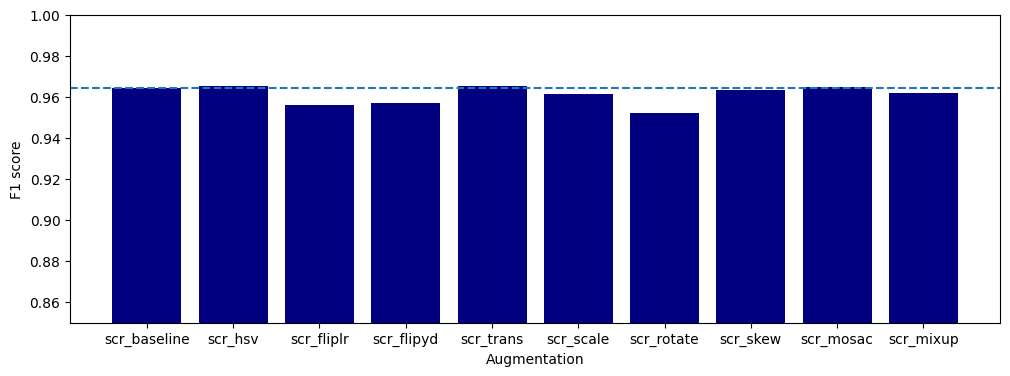

In [9]:
agumen_labels = df["name"]

fig,ax = plt.subplots(figsize=(12,4))
ax.bar(agumen_labels,f1_score, color= "navy")
ax.axhline(y=f1_score[0],linestyle="--")
ax.set_ylim(0.85,1.0)
ax.set_xlabel("Augmentation")
ax.set_ylabel("F1 score")
plt.show()

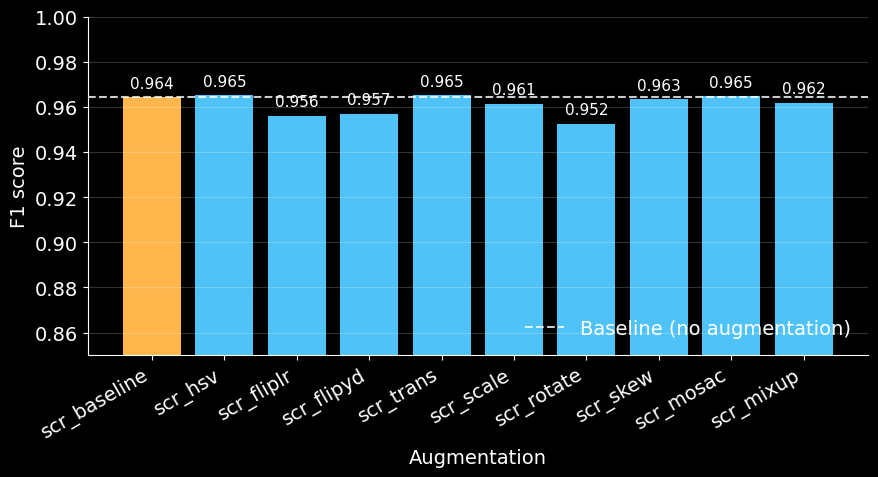

In [14]:
import matplotlib.pyplot as plt

plt.style.use("dark_background")
plt.rcParams.update({"figure.facecolor": "black", "axes.facecolor": "black",
                     "savefig.facecolor": "black", "font.size": 14})

augment_labels = df["name"]
baseline = f1_score[0]

# highlight the baseline bar, other bars in the same light blue as the loss curves
colors = ["#FFB74D"] + ["#4FC3F7"] * (len(augment_labels) - 1)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(augment_labels, f1_score, color=colors)
ax.axhline(y=baseline, color="white", linestyle="--", lw=1.5, alpha=0.8, label="Baseline (no augmentation)")

# value labels on top of each bar
for b, v in zip(bars, f1_score):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.003, f"{v:.3f}",
            ha="center", va="bottom", fontsize=11, color="white")

ax.set_ylim(0.85, 1.0)
ax.set_xlabel("Augmentation")
ax.set_ylabel("F1 score")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", alpha=0.2)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.savefig("augmentation_f1_dark.png", dpi=200)
plt.show()